# $\zeta(3)$: historical constructions and new result

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

**Run status:**

- Rhin–Viola (2001): Depth-500 attempt stopped after 480 seconds.
- Giraudin (2026): Depth 500 requires 26 million Rhin–Viola steps plus corrections; exceeds the cleanup runtime budget.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from ramanujantools.cmf.meijer_g import MeijerG
from cmfs import (
    apery_seeds, dvornicich_viola_zeta3, dvornicich_viola_zeta3_path,
    dvornicich_viola_zeta3_seeds, giraudin_zeta3_walk, numerical_dual_walk,
    staircase_states, zudilin_zeta23_readout, zudilin_zeta23_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
a0, a1, a2, a3, b0, b1, b2, b3 = sp.symbols('a0:4 b0:4')
target = lambda: arb(3).zeta()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Apéry (1978 announcement; 1979 publication): exact source sequences

[Original paper, pp. 12–13](https://www.numdam.org/article/AST_1979__61__11_0.pdf).

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(-2,-2,3,3;1,1,1)$.
**Direction:** $(-1,-1,1,1;0,0,0)$. Source index N uses N−2 steps.
**Readout:** $(PW)_0/(QW)_0$, with $P=(351/4,2683/24,0)$ and $Q=(73,93,0)$.

In [5]:
cmf = pFq(4, 3, 1)
axes = sp.symbols('x0:4') + sp.symbols('y0:3')
start = dict(zip(axes, [-2, -2] + [3] * 2 + [1] * 3))
trajectory = dict(zip(axes, [-1, -1] + [1] * 2 + [0] * 3))
P, Q = apery_seeds(3)
walks = cmf.walk(trajectory, [N - 2 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Apéry (1979), exact source index'] = (DEPTHS, deltas)
accuracy['Apéry (1979), exact source index'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.090440626166


## 2. Dvornicich–Viola (1987; proceedings 1990)

[the original paper](https://mek.oszk.hu/24100/24107/pdf/24107_2.pdf).

**CMF:** rank-8 moments of $\psi^{e_0}(1-34\psi)^{e_1}(1-35\psi)^{e_2}$ for Beukers' integral.
**Start:** $(0,0,0)$. **Path:** $(2\lfloor56.41m\rfloor,2\lfloor1.342m\rfloor,2m)$.
**Readout:** $-C_0/Z_0$ from $S=C+Z\zeta(3)$. The plotted index is m.
The polynomial insertions have no verified single pFq/Meijer G replacement.

In [7]:
cmf = dvornicich_viola_zeta3()
start = dvornicich_viola_zeta3_path(0)
trajectory = dvornicich_viola_zeta3_path
seeds = dvornicich_viola_zeta3_seeds()
walks = staircase_states(cmf, start, trajectory, DEPTHS, seeds)
approximants = [-W[0, 0] / W[1, 0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Dvornicich–Viola (1987)'] = (DEPTHS, deltas)
accuracy['Dvornicich–Viola (1987)'] = [value[1] for value in measurements]
print(f"delta at m = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at m = 500: 0.084432926082


## 3. Hata (1990): recovery unresolved

[Hata's paper](https://doi.org/10.1515/crll.1990.407.99).

**No verified CMF recovery; no delta calculation or final-table row.**

## 4. Hata (2000)

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** Meijer $G$ · **Start:** $(1,1,2,2;1,1,1,1)$ ·
**Direction:** $(0,1,15,16;8,7,8,9)$. We use the direct walk and the
extraction $p_N/q_N=s_1/(4s_0+2s_1)$.

In [10]:
cmf = MeijerG(4, 2, 4, 4, 1)
start = {a0: 1, a1: 1, a2: 2, a3: 2, b0: 1, b1: 1, b2: 1, b3: 1}
trajectory = {a0: 0, a1: 1, a2: 15, a3: 16, b0: 8, b1: 7, b2: 8, b3: 9}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / (4 * W[0, 0] + 2 * W[1, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hata (2000)'] = (DEPTHS, deltas)
accuracy['Hata (2000)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.159318401794


## 5. Rhin–Viola (2001)

[Paper](https://www.impan.pl/shop/en/publication/transaction/download/product/82430).

**CMF:** Meijer $G$ · **Start:** $(1,1,2,2;1,1,1,1)$ ·
**Direction:** $(0,7,31,32;18,17,16,19)$. We use the direct walk and the
extraction $p_N/q_N=s_1/(4s_0+2s_1)$, as for Hata.

In [ ]:
cmf = MeijerG(4, 2, 4, 4, 1)
start = {a0: 1, a1: 1, a2: 2, a3: 2, b0: 1, b1: 1, b2: 1, b3: 1}
trajectory = {a0: 0, a1: 7, a2: 31, a3: 32, b0: 18, b1: 17, b2: 16, b3: 19}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / (4 * W[0, 0] + 2 * W[1, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rhin–Viola (2001)'] = (DEPTHS, deltas)
accuracy['Rhin–Viola (2001)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

Not computed: Depth-500 attempt stopped after 480 seconds.


## 6. Zudilin (2002): simultaneous zeta(2), zeta(3) approximations

[Original paper, Section 3, equation (16) and Theorem 4](https://arxiv.org/abs/math/0206178).

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(3,3,3,3;6,6,6)$.
**Direction:** $(1,1,1,1;2,2,2)$. Source index N uses N−2 steps.
**Readout:** eliminate the $\zeta(2)$ coefficient using the exact determinant readout in `cmfs.py`.

In [14]:
cmf = pFq(4, 3, 1)
axes = sp.symbols('x0:4') + sp.symbols('y0:3')
start = dict(zip(axes, [3] * 4 + [6] * 3))
trajectory = dict(zip(axes, [1] * 4 + [2] * 3))
seeds = zudilin_zeta23_seeds()
walks = cmf.walk(trajectory, [N - 2 for N in DEPTHS], start)
approximants = [zudilin_zeta23_readout(W, N, seeds, 3) for N, W in zip(DEPTHS, walks)]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zudilin (2002), simultaneous'] = (DEPTHS, deltas)
accuracy['Zudilin (2002), simultaneous'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.036403243133


## 7. Dauguet–Zudilin (2014): simultaneous construction

[*On simultaneous diophantine approximations to $\zeta(2)$ and $\zeta(3)$*, Section 3, equations (25)–(30)](https://arxiv.org/abs/1401.5322).

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(1,1,1,0;1,1,1)$.
**Direction:** $(10,9,8,-5;1,2,3)$. Source index N equals the walk length.
**Readout:** $W_{20}/(2W_{00})$. The defining formulas determine the initial values; their discrepancy with the printed denominator values is recorded in `local_checks`.

The simultaneous bound concerns constrained linear forms, not the ordinary irrationality measure.

In [16]:
cmf = pFq(4, 3, 1)
axes = sp.symbols('x0:4') + sp.symbols('y0:3')
start = dict(zip(axes, [1, 1, 1, 0, 1, 1, 1]))
trajectory = dict(zip(axes, [10, 9, 8, -5, 1, 2, 3]))
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[2, 0] / (2 * W[0, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Dauguet–Zudilin (2014)'] = (DEPTHS, deltas)
accuracy['Dauguet–Zudilin (2014)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.039456598696


## 8. Giraudin (2026 preprint)

[*A new upper bound for the irrationality exponent of $\zeta(3)$*](https://arxiv.org/abs/2609.26980).

**CMF:** $G^{4,2}_{4,4}(1)$. **Start:** $(1,1,2,2;1,1,1,1)$.
**Direction:** $(0,363979,1612007,1664004;935996,883999,832002,987993)$.
**Readout:** $W_{10}/(4W_{00}+2W_{10})$.
Each source period uses 52,000 Rhin–Viola steps plus a small correction; the helper preserves the nonsingular path.

In [ ]:
cmf = MeijerG(4, 2, 4, 4, 1)
axes = sp.symbols('a0:4') + sp.symbols('b0:4')
start = dict(zip(axes, [1, 1, 2, 2, 1, 1, 1, 1]))
trajectory = dict(zip(axes, [0, 363979, 1612007, 1664004, 935996, 883999, 832002, 987993]))
walks = giraudin_zeta3_walk(cmf, trajectory, DEPTHS, start)
approximants = [W[1, 0] / (4 * W[0, 0] + 2 * W[1, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Giraudin (2026)'] = (DEPTHS, deltas)
accuracy['Giraudin (2026)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

Not computed: Depth 500 requires 26 million Rhin–Viola steps plus corrections; exceeds the cleanup runtime budget.


## 9. New Meijer $G$ trajectory (this work)

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** Meijer $G$, $G^{5,2}_{5,5}(1)$ · **Start:** $(1,1,0,0,2;0,0,0,0,0)$ ·
**Direction:** $(11,12,-16,-17,10;0,1,2,-1,-2)$. We use the inverse-transpose
walk $(s_0,s_1,s_2,\ldots)$ and the extraction
$p_N/q_N=(-3s_1+3s_2)/(6s_2)$, the first and third rows of
$$\mathcal R_N=\begin{pmatrix}0&-3&3\\2&-2&0\\0&0&6\end{pmatrix}
\begin{pmatrix}s_0\\s_1\\s_2\end{pmatrix}.$$

In [20]:
cmf = MeijerG(5, 2, 5, 5, 1)
axes = sp.symbols('a0:5') + sp.symbols('b0:5')
start = dict(zip(axes, [1, 1, 0, 0, 2, 0, 0, 0, 0, 0]))
trajectory = dict(zip(axes, [11, 12, -16, -17, 10, 0, 1, 2, -1, -2]))
walks = numerical_dual_walk(cmf, trajectory, DEPTHS, start)
approximants = [(-W[1, 0] + W[2, 0]) / (2 * W[2, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New Meijer $G$ trajectory'] = (DEPTHS, deltas)
accuracy['New Meijer $G$ trajectory'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.226980133848


## 10. New trajectory: zeta(4)

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** the same dual $G^{5,2}_{5,5}(1)$ field and trajectory as the new $\zeta(3)$ example.
The cell states the exact scalar readout. N is the walk length; the targets are evaluated independently.

In [22]:
cmf = MeijerG(5, 2, 5, 5, 1)
axes = sp.symbols('a0:5') + sp.symbols('b0:5')
start = dict(zip(axes, [1, 1, 0, 0, 2, 0, 0, 0, 0, 0]))
trajectory = dict(zip(axes, [11, 12, -16, -17, 10, 0, 1, 2, -1, -2]))
walks = numerical_dual_walk(cmf, trajectory, DEPTHS, start)
approximants = [(W[0, 0] - W[1, 0]) / (3 * W[2, 0]) for W in walks]
target = lambda: arb(4).zeta()

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New trajectory: zeta(4)'] = (DEPTHS, deltas)
accuracy['New trajectory: zeta(4)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.016162301055


## 11. New trajectory: 15 zeta(3) + zeta(4)

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** the same dual $G^{5,2}_{5,5}(1)$ field and trajectory as the new $\zeta(3)$ example.
The cell states the exact scalar readout. N is the walk length; the targets are evaluated independently.

In [24]:
cmf = MeijerG(5, 2, 5, 5, 1)
axes = sp.symbols('a0:5') + sp.symbols('b0:5')
start = dict(zip(axes, [1, 1, 0, 0, 2, 0, 0, 0, 0, 0]))
trajectory = dict(zip(axes, [11, 12, -16, -17, 10, 0, 1, 2, -1, -2]))
walks = numerical_dual_walk(cmf, trajectory, DEPTHS, start)
approximants = [(-45 * W[1, 0] + 45 * W[2, 0] + 2 * W[0, 0] - 2 * W[1, 0]) / (6 * W[2, 0]) for W in walks]
target = lambda: 15 * arb(3).zeta() + arb(4).zeta()

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New trajectory: 15 zeta(3) + zeta(4)'] = (DEPTHS, deltas)
accuracy['New trajectory: 15 zeta(3) + zeta(4)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.016135261552


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

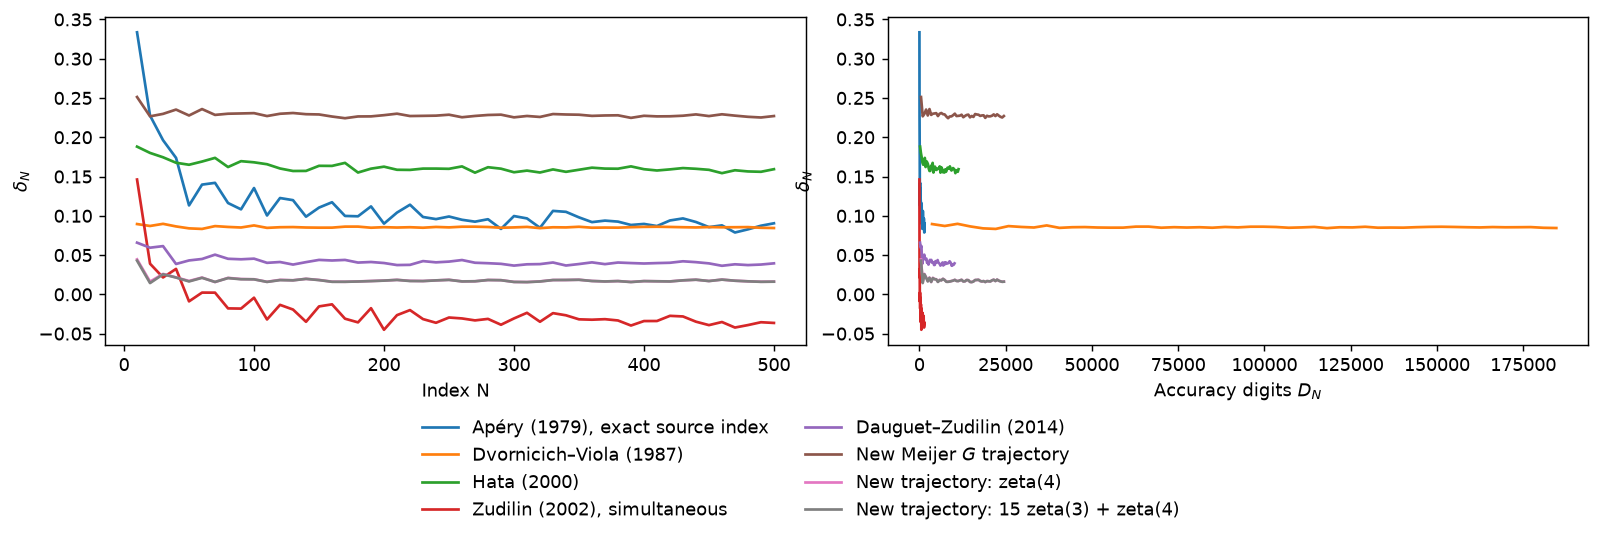

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [28]:
bounds = {
    'Apéry (1979), exact source index': '$13.41782$',
    'Dvornicich–Viola (1987)': '$12.7436$',
    'Hata (2000)': '$7.377956$',
    'Rhin–Viola (2001)': '$5.513891$',
    'Zudilin (2002), simultaneous': 'Convergence; no irrationality bound',
    'Dauguet–Zudilin (2014)': '$s_{\\tau_0}\\le6.770732145\\ldots$ (not $\\mu$)',
    'Giraudin (2026)': '$5.5138800$',
    'New Meijer $G$ trajectory': '5.44019 (manuscript)',
    'New trajectory: zeta(4)': 'Simultaneous readout',
    'New trajectory: 15 zeta(3) + zeta(4)': '64.983 (manuscript, linear forms)',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Apéry (1979), exact source index | $13.41782$ | 0.090440626166 (N = 500) |
| Dvornicich–Viola (1987) | $12.7436$ | 0.084432926082 (N = 500) |
| Hata (2000) | $7.377956$ | 0.159318401794 (N = 500) |
| Rhin–Viola (2001) | $5.513891$ | Not computed |
| Zudilin (2002), simultaneous | Convergence; no irrationality bound | -0.036403243133 (N = 500) |
| Dauguet–Zudilin (2014) | $s_{\tau_0}\le6.770732145\ldots$ (not $\mu$) | 0.039456598696 (N = 500) |
| Giraudin (2026) | $5.5138800$ | Not computed |
| New Meijer $G$ trajectory | 5.44019 (manuscript) | 0.226980133848 (N = 500) |
| New trajectory: zeta(4) | Simultaneous readout | 0.016162301055 (N = 500) |
| New trajectory: 15 zeta(3) + zeta(4) | 64.983 (manuscript, linear forms) | 0.016135261552 (N = 500) |